# Graphite crust on Mercury: paper figures

Final figures for the paper, from the Mercury graphite grid. The working analysis, with more diagnostics, is in `mercury_graphite.ipynb`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import glob
from matplotlib.patches import Circle
from matplotlib.patches import Patch
import cmcrameri.cm as cmc

import utils.load_grid as lg

from proteus.utils.constants import CONDENSATE_SATURATED_ACTIVITY, condensate_density
from proteus.utils.plot import get_colour

%matplotlib inline

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


In [2]:
plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "savefig.dpi": 300, "figure.dpi": 150, "legend.frameon": False,
})

In [14]:
pgrid_dir = "data/scratch/mercury_graphite_grid_v24"

# Index into the grid's planet.mass_tot axis: 0 is 1x Mercury, 1 is 2.475x Mercury
MASS_IDX = 0

outdir = os.path.join("output", "paper_figures", f"{os.path.basename(pgrid_dir)}_mass{MASS_IDX:d}")
os.makedirs(outdir, exist_ok=True)

SATURATED = CONDENSATE_SATURATED_ACTIVITY   # graphite activity at and above which it is saturated
RHO_GRAPHITE = condensate_density["C"]      # [kg m-3]
CRUST_MIN_M = 1e-3                          # thinner graphite layers count as no crust [m]
STATUS_SOLIDIFIED = 10                      # run ended because the mantle solidified

# Mercury's surface fO2 from sulfur (Sossi) [delta IW]
SOSSI_DIW = -5.0

# Graphite-equivalent thickness of the low-reflectance material (LRM) [m]
NAMUR_M = (40.0, 120.0)                     # Namur (2026)

# Lark et al. (2023): LRM layer 4-15 km thick with 2-7 wt% graphite, crustal density 2979 kg m-3;
# per-basin bounds on the layer thickness from their Table 3 [km]
LARK_RHO_CRUST = 2979.0                     # [kg m-3]
LARK_WT = (0.02, 0.07)                      # graphite mass fraction in the LRM
LARK_LAYER_KM = (4.0, 15.0)
LARK_BASINS = [("Caloris", 6.0, "lower"), ("Caloris", 10.0, "upper"),
               ("b56", 8.0, "lower"), ("b30", 15.0, "lower"),   # Lennon-Picasso, Calder-Hodgkins
               ("Sobkou", 5.0, "lower"), ("Rembrandt", 6.0, "lower")]

def lark_graphite_m(layer_km, wt):
    """Graphite-equivalent thickness [m] of an LRM layer [km] holding mass fraction wt of graphite."""
    return LARK_RHO_CRUST * layer_km * 1e3 * wt / RHO_GRAPHITE

LARK_M = (lark_graphite_m(LARK_LAYER_KM[0], LARK_WT[0]), lark_graphite_m(LARK_LAYER_KM[1], LARK_WT[1]))

# Nominal EH chondrite [ppmw of the whole planet]
C_EHCHONDRITE = 5541.2

# Metal/silicate partition coefficient of C from Namur (2026), Eqs. 20-22: shifted sigmoids in
# delta IW with (L, k, x0, x_shift, y_target); they use 26 GPa for a more massive proto-Mercury
NAMUR_DC_FITS = {"5-6 GPa": (184.0, 4.03, -4.77, -8.5, 1.0), "26 GPa": (3.29, 118.0, -5.34, -8.5, 0.5)}
NAMUR_DC_FIT = "5-6 GPa" if MASS_IDX == 0 else "26 GPa"
DC_DIW = SOSSI_DIW   # fO2 at which the core equilibrates, for the printed bulk carbon [delta IW]

def namur_dc(diw, fit=NAMUR_DC_FIT):
    """Metal/silicate C concentration ratio at fO2 diw [delta IW] (Namur 2026, Eqs. 20-22)."""
    L, k, x0, x_shift, y_target = NAMUR_DC_FITS[fit]
    sig = lambda x: L / (1.0 + np.exp(-k * (x - x0)))
    return sig(diw) - (sig(x_shift) - y_target)

# Magma ocean solidification times from Jaggi et al. (2021) [yr]
JAGGI_YR = (3400.0, 8900.0)

print(f"Namur: {NAMUR_M[0]:.0f}-{NAMUR_M[1]:.0f} m; Lark: {LARK_M[0]:.0f}-{LARK_M[1]:.0f} m graphite")

Namur: 40-120 m; Lark: 105-1384 m graphite


In [4]:
cases = lg.get_cases(pgrid_dir, only_completed=False)
cfgs = lg.load_configs(cases)

# Keep the cases at the chosen planet mass; helpfiles are read for these only
mass = np.array(lg.access_configs(cfgs, "planet.mass_tot"), dtype=float)
MASS_VALUES = np.unique(mass)
MASS_TOT = MASS_VALUES[MASS_IDX]
keep = np.isclose(mass, MASS_TOT, rtol=1e-6, atol=0.0)
cases = [c for c, k in zip(cases, keep) if k]
cfgs = [c for c, k in zip(cfgs, keep) if k]
print(f"Planet mass {MASS_TOT:g} M_earth: {len(cases)} of {len(keep)} cases")

helps, _ = lg.load_helpfiles(cases)
print("Done!")

Configs:   0%|          | 0/384 [00:00<?, ?it/s]outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false
Configs:   0%|          | 1/384 [00:04<25:45,  4.03s/it]outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect wit

Planet mass 0.0553 M_earth: 192 of 384 cases


Helpfiles: 100%|██████████| 192/192 [00:07<00:00, 24.42it/s]


Done!


In [15]:
def cfg_array(key, dtype=float):
    return np.array(lg.access_configs(cfgs, key), dtype=dtype)

dIW = cfg_array("outgas.fO2_shift_IW")
Cb = cfg_array("planet.elements.C_budget")
cond = cfg_array("outgas.atmodeller.include_condensates", bool)
eta = cfg_array("escape.zephyrus.efficiency")
status = np.array([lg.get_status(c) for c in cases])
ETA_OFF, ETA_ON = np.unique(eta)

COLS = ["Time", "C_cd_activity", "C_cd_kg", "R_int", "Phi_global", "M_core", "M_mantle"]

rows, series = [], {}
for case, hf, x, y, on, e, s in zip(cases, helps, dIW, Cb, cond, eta, status):
    ts = {k: np.array(hf[k], dtype=float) for k in COLS}
    ts["thick"] = ts["C_cd_kg"] / (4.0 * np.pi * ts["R_int"] ** 2) / RHO_GRAPHITE   # [m]
    series[(x, y, on, e)] = ts
    sat = np.flatnonzero(ts["C_cd_activity"] >= SATURATED)
    rows.append(dict(case=os.path.basename(case), dIW=x, C=y, cond=on, eta=e, status=s,
                     t_end=ts["Time"][-1], thick_end=ts["thick"][-1],
                     t_sat_start=ts["Time"][sat[0]] if len(sat) else np.nan,
                     t_sat_stop=ts["Time"][sat[-1]] if len(sat) else np.nan))
# Bulk carbon over the initial mantle concentration, with the core at C_core = D_C * C_mantle
M_CORE, M_MANTLE = (series[next(iter(series))][k][0] for k in ("M_core", "M_mantle"))   # [kg]
DC = namur_dc(DC_DIW)
BULK_PER_MANTLE = (M_MANTLE + DC * M_CORE) / (M_MANTLE + M_CORE)
print(f"D_C = {DC:.3g} at dIW = {DC_DIW:g} ({NAMUR_DC_FIT} fit); core mass fraction "
      f"{M_CORE / (M_CORE + M_MANTLE):.3f}; bulk C = {BULK_PER_MANTLE:.3g} x mantle C")

# Bulk carbon [wt%] of each initial mantle concentration, at every fO2 of the grid; the core
# carbon C_core = D_C * C_mantle is not capped at metal saturation
dc_grid = pd.Series({x: namur_dc(x) for x in np.unique(dIW)}, name="D_C")
bulk_wt = pd.DataFrame({x: np.unique(Cb) * (M_MANTLE + d * M_CORE) / (M_MANTLE + M_CORE) / 1e4
                        for x, d in dc_grid.items()}, index=pd.Index(np.unique(Cb), name="mantle ppmw"))
bulk_wt.columns.name = "dIW"
print(f"D_C ({NAMUR_DC_FIT} fit):\n{dc_grid.to_frame().T.to_string(float_format=lambda v: f'{v:.3g}')}")
print(f"Bulk planet carbon [wt%]:\n{bulk_wt.to_string(float_format=lambda v: f'{v:.3g}')}")
print(f"Core carbon [wt%] at dIW = {DC_DIW:g}: "
      + ", ".join(f"{c:g} -> {c * DC / 1e4:.3g}" for c in np.unique(Cb)))

summary = pd.DataFrame(rows).sort_values(["cond", "eta", "dIW", "C"]).reset_index(drop=True)

xs = np.unique(dIW)                  # fO2 values [delta IW]
cmap_fO2 = cmc.batlow                # reversed: pale at low fO2; palest end left out
COL_FO2 = {x: cmap_fO2(0.85 * (1 - i / max(len(xs) - 1, 1))) for i, x in enumerate(xs)}

# Saturation and escape on: the arm shown in the figures
base = summary[summary["cond"] & (summary["eta"] == ETA_ON)]
print(base[["dIW", "C", "status", "t_end", "thick_end"]].to_string(index=False))

D_C = 53.2 at dIW = -5 (5-6 GPa fit); core mass fraction 0.746; bulk C = 39.9 x mantle C
D_C (5-6 GPa fit):
     -6.0  -5.5  -5.0  -4.5  -4.0  -3.5
D_C  2.29  10.2  53.2   139   177   184
Bulk planet carbon [wt%]:
dIW            -6.0   -5.5  -5.0  -4.5  -4.0  -3.5
mantle ppmw                                       
30.0        0.00588 0.0236  0.12 0.311 0.397 0.412
100.0        0.0196 0.0788 0.399  1.04  1.32  1.37
300.0        0.0588  0.236   1.2  3.11  3.97  4.12
1000.0        0.196  0.788  3.99  10.4  13.2  13.7
2000.0        0.392   1.58  7.98  20.7  26.5  27.5
3000.0        0.588   2.36    12  31.1  39.7  41.2
5541.2         1.09   4.37  22.1  57.4  73.3  76.1
10000.0        1.96   7.88  39.9   104   132   137
Core carbon [wt%] at dIW = -5: 30 -> 0.16, 100 -> 0.532, 300 -> 1.6, 1000 -> 5.32, 2000 -> 10.6, 3000 -> 16, 5541.2 -> 29.5, 10000 -> 53.2
 dIW       C  status        t_end    thick_end
-6.0    30.0      10 1.005341e+03 3.734457e-24
-6.0   100.0      10 1.000093e+03 1.617744e

## Figure 1: graphite crust thickness against the LRM constraints

Saturation and escape on. **(a)** Final graphite crust thickness against the initial carbon concentration of the mantle, one line per fO2, one point per run. Filled points: the run ended when the mantle solidified; open points: it stopped earlier (atmosphere escaped, or run died or still running), so the crust is that at the time it stopped. The thickness axis is linear below 10 m, so runs without a crust sit at zero. The dotted line marks the nominal Mercury carbon budget (EH chondrite, 5541.2 ppmw of the whole planet). Shaded: the graphite-equivalent LRM thickness of Namur (2026) and of Lark et al. (2023) (4-15 km of LRM with 2-7 wt% graphite). The middle strip shows the per-basin bounds of Lark et al. (2023, Table 3) on the LRM layer thickness, each converted with 2 wt% (lower marker) and 7 wt% graphite (upper marker): upward triangles are lower bounds; Caloris also has an upper bound (downward triangles), and its lower and upper bounds are joined at each graphite fraction. Basins b56 and b30 are Lennon-Picasso and Calder-Hodgkins. The favourite run (star) is the run at the Sossi fO2 whose crust is closest, in log, to the geometric centre of the thickness range both Namur and Lark allow (their overlap, 105-120 m).

**(b)** Crust thickness against time for the runs at the Sossi fO2; runs without a crust stay at zero and are labelled where they end. Circles, labelled with the initial mantle carbon: the last time the graphite is saturated, after which the crust is held. Vertical lines: magma ocean solidification times from Jaggi et al. (2021).

      C  status   thick_end  log_distance
 2000.0      10   80.092023      0.147527
 3000.0      10  576.904133      0.709987
 5541.2      10 1584.063772      1.148656
10000.0      15 3210.961453      1.455518
Target 112 m; favourite: dIW = -5, C = 2000 ppmw, crust 80 m, case_000166


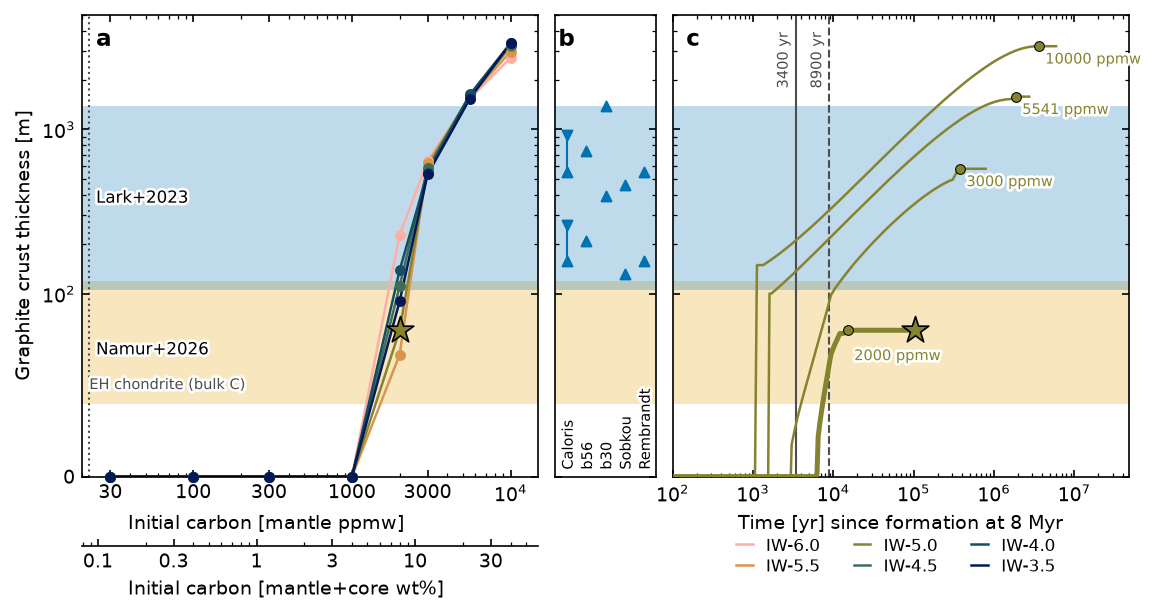

In [49]:
# Favourite run: at the Sossi fO2, crust closest in log to the centre of the thickness range that
# both constraints allow (of the gap between them, if they do not overlap)
sossi = base[np.isclose(base["dIW"], SOSSI_DIW) & (base["thick_end"] > CRUST_MIN_M)]
target_m = np.sqrt(max(NAMUR_M[0], LARK_M[0]) * min(NAMUR_M[1], LARK_M[1]))
fav = sossi.iloc[np.argmin(np.abs(np.log10(sossi["thick_end"] / target_m)))]
print(sossi[["C", "status", "thick_end"]].assign(log_distance=np.abs(np.log10(sossi["thick_end"] / target_m))).to_string(index=False))
print(f"Target {target_m:.0f} m; favourite: dIW = {fav.dIW:g}, C = {fav.C:g} ppmw, "
      f"crust {fav.thick_end:.0f} m, {fav.case}")

STROKE = [pe.withStroke(linewidth=2.5, foreground="w")]
Y_LINTHRESH_M, Y_MAX_M = 1e2, 5e3   # thickness axis: linear below LINTHRESH, top [m]

ini_age = lg.access_configs(cfgs, "star.age_ini")[0] *1e9 / 1e6   # [Myr]

col_lark = "#0072B2"   # Lark et al. (2023) per-basin bounds
col_namur = "#E69F00"  # Namur (2026) LRM thickness range

def constraint_bands(ax, labels):
    """Shaded Namur and Lark ranges, with their names written on them when labels is true."""
    for (lo, hi), col, name in ((NAMUR_M, col_namur, "Namur+2026"),
                                (LARK_M, col_lark, "Lark+2023")):
        ax.axhspan(lo, hi, color=col, alpha=0.25, lw=0, zorder=0)
        if labels:
            ax.text(0.03, np.sqrt(lo * hi), name, transform=ax.get_yaxis_transform(),
                    ha="left", va="center", fontsize=8, color="k", path_effects=STROKE, zorder=5)

wt_ppmw_map = (
                lambda x: x * BULK_PER_MANTLE / 1e6 * 1e2,  # map from bulk planet carbon [wt%] to initial mantle ppmw
                lambda x: x * 1e6 / 1e2 / BULK_PER_MANTLE   # inverse ^
               )

def panel_thickness_vs_C(ax):

    # for each dIW
    for x in xs:

        # get thickness and plot
        d = base[np.isclose(base["dIW"], x)]
        ax.plot(d["C"], d["thick_end"], color=COL_FO2[x], lw=1.2, zorder=2, label=f"IW{x:+.1f}")
        ax.scatter(d["C"], d["thick_end"], s=18, color=COL_FO2[x], zorder=3, clip_on=False)
    
    # add eh chondrite line bulk C wt% and label
    ax.axvline(wt_ppmw_map[0](C_EHCHONDRITE), color="0.3", ls=":", lw=1.0, zorder=1)
    ax.text(wt_ppmw_map[0](C_EHCHONDRITE), 0.5 * Y_LINTHRESH_M, 
            "EH chondrite (bulk C)", ha="left", va="center",
            fontsize=7, color="0.3", path_effects=STROKE)
    
    # indicate favourite
    ax.scatter(fav.C, fav.thick_end, marker="*", s=180, color=COL_FO2[SOSSI_DIW],
               edgecolor="k", lw=0.8, zorder=4)
    
    # Shaded Namur and Lark ranges, with their names written on them when labels is true
    constraint_bands(ax, labels=True)

    # pretty
    ax.set_xscale("log")
    ax.legend(loc="upper left", 
              bbox_to_anchor=(1.4, -0.1), ncol=3,
              fontsize=8, handlelength=1.0, handleheight=1.0, labelspacing=0.2,)

    # x range and ticks from the grid's carbon budgets
    c_lo, c_hi = base["C"].min(), base["C"].max()
    ax.set_xlim(c_lo / 1.5, c_hi * 1.5)
    ticks = [v for v in (10, 30, 100, 300, 1000, 3000, 1e4, 3e4, 1e5) if c_lo <= v <= c_hi]
    def tick_label(v):
        """Plain below 10^4, else m x 10^n."""
        if v < 1e4:
            return f"{v:g}"
        n = int(np.floor(np.log10(v)))
        m = v / 10 ** n
        return rf"$10^{{{n}}}$" if np.isclose(m, 1) else rf"${m:g}\times10^{{{n}}}$"
    ax.set_xticks(ticks, [tick_label(v) for v in ticks])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("Initial carbon [mantle ppmw]", ha='left', x=0.1)
    ax.set_ylabel("Graphite crust thickness [m]")

    # Second axis below: bulk planet carbon, with the core at C_core = D_C * C_mantle (not capped
    # at metal saturation); D_C from Namur (2026) at DC_DIW
    bulk = ax.secondary_xaxis(-0.15, functions=wt_ppmw_map)
    w_lo, w_hi = (v * BULK_PER_MANTLE / 1e4 for v in ax.get_xlim())
    w_ticks = [v for v in (0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100) if w_lo <= v <= w_hi]
    bulk.set_xticks(w_ticks, [f"{v:g}" for v in w_ticks])
    bulk.xaxis.set_minor_formatter(plt.NullFormatter())
    bulk.set_xlabel(rf"Initial carbon [mantle+core wt%]", ha='left', x=0.1)

def panel_lark_basins(ax):
    """Per-basin bounds of Lark et al. (2023), each converted with the low and high graphite fraction."""
    constraint_bands(ax, labels=False)
    names = list(dict.fromkeys(b[0] for b in LARK_BASINS))
    for name, km, kind in LARK_BASINS:
        i = names.index(name)
        lo, hi = (lark_graphite_m(km, w) for w in LARK_WT)
        ax.scatter([i, i], [lo, hi], marker="^" if kind == "lower" else "v", s=22,
                   color=col_lark, zorder=3)
    # Caloris has both bounds: join them at each graphite fraction
    cal = {kind: km for name, km, kind in LARK_BASINS if name == "Caloris"}
    for w in LARK_WT:
        ax.plot([0, 0], [lark_graphite_m(cal["lower"], w), lark_graphite_m(cal["upper"], w)],
                color=col_lark, lw=1.0, zorder=2)
    ax.set_xlim(-0.6, len(names) - 0.4)
    for i, name in enumerate(names):
        ax.text(i + 0.1, 0.015, name, rotation=90, ha="center", va="bottom", fontsize=7,
                transform=ax.get_xaxis_transform(), path_effects=STROKE)
    ax.set_xticks([])

def panel_thickness_vs_time(ax):
    col = COL_FO2[SOSSI_DIW]
    constraint_bands(ax, labels=False)
    for _, r in base[np.isclose(base["dIW"], SOSSI_DIW)].iterrows():
        ts = series[(r.dIW, r.C, True, ETA_ON)]
        ok = ts["Time"] > 0
        t, th = ts["Time"][ok], ts["thick"][ok]
        is_fav = r.case == fav.case
        ax.plot(t, th, color=col, lw=2.4 if is_fav else 1.2, zorder=3 if is_fav else 2)
        if r.thick_end <= CRUST_MIN_M:   # no crust: stays on the zero line, labelled together below
            continue
        # last saturated time: the crust is held from here on
        k = min(np.searchsorted(t, r.t_sat_stop), len(t) - 1)
        ax.scatter(t[k], th[k], marker="o", s=22, color=col, edgecolor="k", lw=0.5, zorder=4)
        ax.annotate(f"{r.C:.0f} ppmw", 
                    (t[k], th[k]),
                    xytext=(3, -9 if is_fav else -3), textcoords="offset points", ha="left", va="top", fontsize=7,
                    color=col, path_effects=STROKE, zorder=5)
        if is_fav:
            ax.scatter(t[-1], th[-1], marker="*", s=180, color=col, edgecolor="k", lw=0.8, zorder=5)
    # no_crust = base[np.isclose(base["dIW"], SOSSI_DIW) & (base["thick_end"] <= CRUST_MIN_M)]
    # if len(no_crust):
    #     ax.text(no_crust["t_end"].max() * 1.2, 1.0, f"{no_crust['C'].min():g}-{no_crust['C'].max():g} ppmw:\nno crust",
    #             ha="left", va="bottom", fontsize=6, color=col, path_effects=STROKE)
    for t_j, ls in zip(JAGGI_YR, ("-", "--")):
        ax.axvline(t_j, color="0.3", ls=ls, lw=1.0, zorder=1)
        ax.text(t_j * 0.88, 0.97, f"{t_j:.0f} yr", rotation=90, ha="right", va="top",
                transform=ax.get_xaxis_transform(), fontsize=7, color="0.3", path_effects=STROKE)
    ax.set_xscale("log")
    ax.set_xlim(1e2, 8 * max(sossi["t_end"]))
    ax.set_xlabel(f"Time [yr] since formation at {ini_age:.0f} Myr")

fig,(ax_a, ax_l, ax_b) = plt.subplots(1, 3, 
                                    sharey=True,
                                      figsize=(9, 4),width_ratios=[1.0, 0.22, 1.0])
panel_thickness_vs_C(ax_a)
panel_lark_basins(ax_l)
panel_thickness_vs_time(ax_b)
ax_a.set_yscale("symlog", linthresh=Y_LINTHRESH_M)
ax_a.set_ylim(0, Y_MAX_M)
ax_a.yaxis.set_minor_locator(mpl.ticker.SymmetricalLogLocator(base=10, linthresh=Y_LINTHRESH_M,
                                                              subs=np.arange(2, 10)))
for ax, letter in ((ax_a, "a"), (ax_l, "b"), (ax_b, "c")):
    ax.text(0.03, 0.97, letter, transform=ax.transAxes, fontweight="bold", fontsize=11,
            ha="left", va="top")

fig.subplots_adjust(wspace=0.05)
fig.savefig(os.path.join(outdir, "fig1_crust_thickness.pdf"), bbox_inches="tight")
plt.show()

## Figure 2: where the initial carbon ends up, with saturation and escape on and off

Runs at the Sossi fO2 (`SOSSI_DIW`) of the loaded planet mass (`MASS_IDX`; 0 is 1x Mercury). One panel per combination of graphite saturation and escape, one bar per initial mantle carbon concentration. Each bar splits the initial carbon at the end of the run into graphite, the carbon in atmospheric CO, CO$_2$ and CH$_4$, and the carbon lost to escape (the drop in the total carbon inventory). Carbon dissolved in the melt or trapped in the solid is left out: it is below the fraction printed under the figure. A star marks a run that did not end by solidifying (atmosphere escaped, run died, or still running): its bar is the partition when it stopped.

Largest |closure| 2.51e-05; largest melt + trapped fraction 5.42e-05; most negative escaped fraction 0.00e+00
(4,)


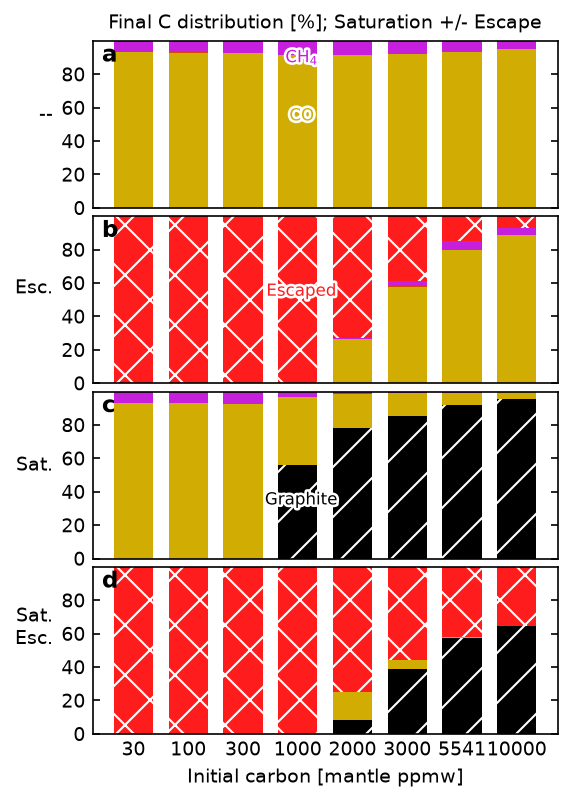

                   graphite    CO  CO2  CH4  escaped  status
cond  eta C                                                 
False 0.0 30.0          0.0  93.3  0.1  6.6      0.0      10
          100.0         0.0  93.0  0.1  6.9      0.0      10
          300.0         0.0  92.7  0.1  7.2      0.0      10
          1000.0        0.0  91.7  0.1  8.2      0.0      10
          2000.0        0.0  91.7  0.1  8.3      0.0      10
          3000.0        0.0  92.0  0.1  7.9      0.0      10
          5541.2        0.0  93.5  0.1  6.4      0.0      10
          10000.0       0.0  95.2  0.1  4.7      0.0      10
      0.1 30.0          0.0   0.0  0.0  0.0    100.0      15
          100.0         0.0   0.0  0.0  0.0    100.0      15
          300.0         0.0   0.0  0.0  0.0    100.0      15
          1000.0        0.0   0.0  0.0  0.0    100.0      15
          2000.0        0.0  26.7  0.0  0.6     72.7      10
          3000.0        0.0  57.9  0.0  3.4     38.6      10
          5541.2        

In [7]:
from proteus.utils.constants import element_mmw

# Elements in each carbon-bearing atmospheric species
C_SPECIES = {"CO": {"C": 1, "O": 1}, "CO2": {"C": 1, "O": 2}, "CH4": {"C": 1, "H": 4}}

def carbon_mass_fraction(comp):
    """Mass fraction of carbon in a molecule of the given elemental composition."""
    return comp["C"] * element_mmw["C"] / sum(n * element_mmw[el] for el, n in comp.items())

# Reservoirs, stacked from the bottom: (key, label, colour, hatch)
C_RESERVOIRS = {"graphite": ("graphite", "Graphite", "#000000", "/"),
                "CO": ("CO", "CO", get_colour("CO"), ""),
                "CO2": ("CO2", "CO$_2$", get_colour("CO2"), ""),
                "CH4": ("CH4", "CH$_4$", get_colour("CH4"), ""),
                "escaped": ("escaped", "Escaped", "#FF1C1C", "x")}


def carbon_endpoint(hf):
    """Fractions of the initial carbon in each reservoir at the last output time."""
    r0, r1 = hf.iloc[0], hf.iloc[-1]
    c0 = float(r0["C_kg_total"])
    kg = {"graphite": r1["C_kg_condensed"], "escaped": c0 - r1["C_kg_total"],
          "melt": r1["C_kg_liquid"] + r1["C_kg_solid"] + r1["C_kg_trapped"]}
    kg.update({sp: r1[f"{sp}_kg_atm"] * carbon_mass_fraction(comp) for sp, comp in C_SPECIES.items()})
    frac = {k: float(v) / c0 for k, v in kg.items()}
    frac["closure"] = sum(frac.values()) - 1.0   # zero when the reservoirs add up to the initial carbon
    return frac

rows = []
for hf, x, y, on, e, s in zip(helps, dIW, Cb, cond, eta, status):
    if np.isclose(x, SOSSI_DIW):
        rows.append(dict(C=y, cond=on, eta=e, status=s, **carbon_endpoint(hf)))
part = pd.DataFrame(rows).sort_values(["cond", "eta", "C"]).reset_index(drop=True)
print(f"Largest |closure| {part['closure'].abs().max():.2e}; largest melt + trapped fraction "
      f"{part['melt'].max():.2e}; most negative escaped fraction {part['escaped'].min():.2e}")

ARMS = [(False, ETA_OFF), (False, ETA_ON), (True, ETA_OFF), (True, ETA_ON)]
C_v = np.unique(Cb)
pos = np.arange(len(C_v))

fig, axs = plt.subplots(4,1, figsize=(4,6), sharex=True, sharey=True)
print(np.shape(axs))
for ax, (on, e), letter in zip(axs.flat, ARMS, "abcd"):
    d = part[(part["cond"] == on) & (part["eta"] == e)].set_index("C").reindex(C_v)
    bottom = np.zeros(len(C_v))
    for key in C_RESERVOIRS.keys():
        _, _, col, hatch = C_RESERVOIRS[key]
        v = 100 * np.clip(d[key].fillna(0.0).to_numpy(), 0.0, None)   # round-off below zero dropped
        ax.bar(pos, v, bottom=bottom, width=0.72, color=col, lw=0, hatch=hatch, hatchcolor='w')
        bottom += v

    ylbl = f"{'Sat.' if on else ''}{'\nEsc.' if e > 0 else ''}"
    if ylbl == "":
        ylbl = "--"
    ax.set_ylabel(ylbl, ha='right', rotation=0)
    ax.text(0.02, 0.98, letter, transform=ax.transAxes, fontweight="bold", fontsize=11,
            ha="left", va="top")
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 20, 40, 60, 80])
    ax.tick_params(axis="x", which="both", top=False, bottom=False)
    ax.tick_params(axis="y", which="minor", left=False, right=False)

axs[0].annotate("CO", (0.45, 0.5), color=C_RESERVOIRS["CO"][2], 
                      xycoords="axes fraction", ha="center", va="bottom", fontsize=8, path_effects=STROKE)
axs[0].annotate("CH$_4$", (0.45, 0.95), color=C_RESERVOIRS["CH4"][2], 
                      xycoords="axes fraction", ha="center", va="top", fontsize=8, path_effects=STROKE)
axs[1].annotate("Escaped", (0.45, 0.5), color=C_RESERVOIRS["escaped"][2], 
                      xycoords="axes fraction", ha="center", va="bottom", fontsize=8, path_effects=STROKE)
axs[2].annotate("Graphite", (0.45, 0.3), color=C_RESERVOIRS["graphite"][2], 
                      xycoords="axes fraction", ha="center", va="bottom", fontsize=8, path_effects=STROKE)
        

axs[-1].set_xticks(pos, [f"{c:.0f}" for c in C_v])
axs[-1].set_xlabel("Initial carbon [mantle ppmw]")
axs[0].set_title("Final C distribution [%]; Saturation +/- Escape", rotation=0)

fig.subplots_adjust(hspace=0.05)
fig.savefig(os.path.join(outdir, "fig2_carbon_partition.pdf"), bbox_inches="tight")
plt.show()

table = part.set_index(["cond", "eta", "C"])[[k for k in C_RESERVOIRS.keys()] + ["status"]]
print((table.drop(columns="status") * 100).round(1).assign(status=table["status"]).to_string())

## Figure 3: atmospheric structure and composition of the favourite run

The favourite run of Figure 1, from AGNI's output at a few times (`FIG3_TIMES_YR`, nearest output used), coloured by time, against pressure with the surface on the left. **(a)** Temperature; the line is thick where the atmosphere convects (a model cell with convective flux at either bounding level). Circles mark the surface temperature and squares the magma (mantle top) temperature, both at the surface pressure; they coincide before a graphite crust forms. **(b)** Height above the surface, with the XUV absorption radius R$_\mathrm{XUV}$ of escape marked (black-edged points). Each profile is linked from its top to a pie of its surface volume mixing ratios, with the time of the profile beside the pie.

R$_\mathrm{XUV}$ is read from the helpfile and marked at the pressure of the profile at that radius. The configured `p_xuv` (5 Pa) is above the top cell centre of the AGNI grid (about 20 Pa), so in this run R$_\mathrm{XUV}$ sits at the top of the model column.


In [8]:
FIG3_TIMES_YR = [0.0, 2e3, 5e3, 2e4, 1e5, np.inf]   # snapshot times, nearest AGNI output used [yr]

# Pie slices: (species, label, colour); everything else is "Other"
PIE_SPECIES = [("CO", "CO", get_colour("CO")), 
               ("CO2", "CO$_2$", get_colour("CO2")),
               ("H2", "H$_2$", get_colour("H2")),
               ("H2S", "H$_2$S", get_colour("H2S")), 
               ("S2", "S$_2$", get_colour("S2"))]
PIE_OTHER = ("Other gas", "#BBBBBB")

fav_dir = cases[[os.path.basename(c) for c in cases].index(fav.case)]
fav_hf = helps[[os.path.basename(c) for c in cases].index(fav.case)]

def nc_time(f):
    """Model time [yr] in the name of an AGNI output file."""
    return float(os.path.basename(f).split("_")[0].replace("p", "."))

nc_files = sorted(glob.glob(os.path.join(fav_dir, "data", "*_atm.nc")), key=nc_time)
nc_t = np.array([nc_time(f) for f in nc_files])
pick = sorted({int(np.argmin(np.abs(nc_t - min(t, nc_t[-1])))) for t in FIG3_TIMES_YR})
# a snapshot within a factor of 2 in time of the final one repeats it; keep the final one only
pick = [i for i in pick if i == pick[-1] or nc_t[i] < 0.5 * nc_t[pick[-1]]]

snaps = []
for i in pick:
    a = lg.readncdf(nc_files[i])
    hf_row = fav_hf.iloc[int(np.argmin(np.abs(fav_hf["Time"] - nc_t[i])))]
    z = (a["rl"] - a["rl"][-1]) / 1e3                                 # height above surface [km]
    z_xuv = (hf_row["R_xuv"] - a["rl"][-1]) / 1e3                     # [km]
    p_at_xuv = 10 ** np.interp(z_xuv, z[::-1], np.log10(a["pl"][::-1]))   # [Pa]
    conv_lev = a["fl_cnvct"] > 0.0                                     # convective levels
    vmr = dict(zip(a["gases"], a["x_gas"][-1]))                        # surface layer
    snaps.append(dict(t=nc_t[i], p=a["pl"] / 1e5, T=a["tmpl"], z=z,
                      conv_cell=conv_lev[:-1] | conv_lev[1:],          # cell j spans levels j, j+1
                      p_surf=a["psurf"] / 1e5, T_surf=a["tmp_surf"], T_magma=float(hf_row["T_magma"]),
                      z_xuv=z_xuv, p_xuv=p_at_xuv / 1e5, vmr=vmr))
    print(f"t = {nc_t[i]:10.4g} yr: T_surf {a['tmp_surf']:6.0f} K, T_magma {hf_row['T_magma']:6.0f} K, "
          f"P_surf {a['psurf'] / 1e5:6.1f} bar, top {z[0]:7.0f} km, {conv_lev.sum()} convective levels; "
          + ", ".join(f"{s} {vmr[s]:.3f}" for s, *_ in PIE_SPECIES))


t =          1 yr: T_surf   3820 K, T_magma   3820 K, P_surf  248.5 bar, top   32325 km, 2 convective levels; CO 0.527, CO2 0.000, H2 0.290, H2S 0.015, S2 0.005
t =       1991 yr: T_surf   2658 K, T_magma   2658 K, P_surf  144.1 bar, top   27020 km, 2 convective levels; CO 0.503, CO2 0.000, H2 0.320, H2S 0.015, S2 0.001
t =       4949 yr: T_surf   2161 K, T_magma   2161 K, P_surf   83.1 bar, top   13195 km, 5 convective levels; CO 0.471, CO2 0.000, H2 0.356, H2S 0.014, S2 0.000
t =   2.14e+04 yr: T_surf   1599 K, T_magma   1959 K, P_surf   62.3 bar, top    3145 km, 11 convective levels; CO 0.362, CO2 0.000, H2 0.440, H2S 0.020, S2 0.000
t =  1.046e+05 yr: T_surf   1593 K, T_magma   1959 K, P_surf   77.9 bar, top    1985 km, 12 convective levels; CO 0.281, CO2 0.000, H2 0.358, H2S 0.201, S2 0.008


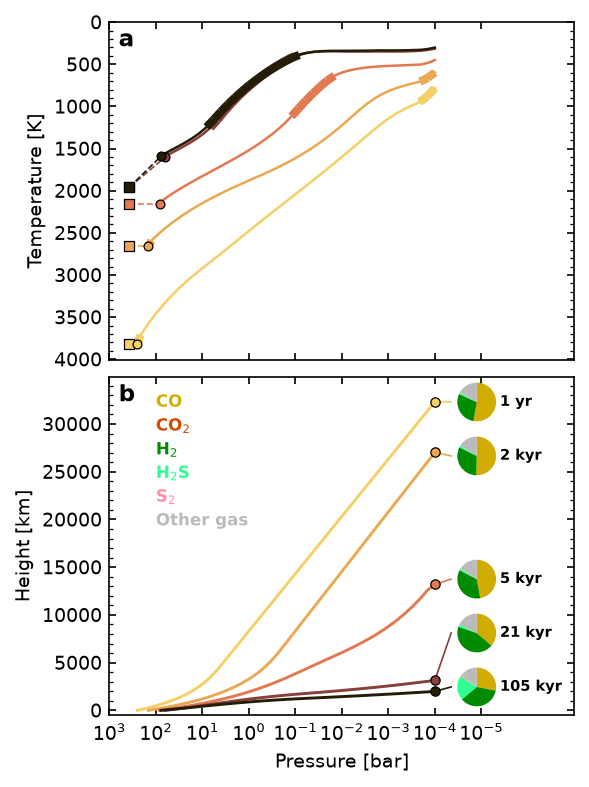

In [9]:
# Log-time colour scale from FIG3_T_COLOUR_MIN_YR, before which the run barely changes;
# earlier snapshots take the first colour
FIG3_T_COLOUR_MIN_YR = 1e3
t_norm = mpl.colors.LogNorm(FIG3_T_COLOUR_MIN_YR, snaps[-1]["t"], clip=True)
cmap_t = cmc.lajolla
col_t = lambda t: cmap_t(0.85 - 0.8 * t_norm(max(t, 1.0)))   # early and hot: pale; late: near black
fmt_t = lambda t: f"{t:.0f} yr" if t < 1e3 else f"{t / 1e3:.0f} kyr"

p_bot = max(s["p_surf"] for s in snaps) * 1.5

fig, (ax_a, ax_b) = plt.subplots(2,1, figsize=(4,6), sharex=True)
for s in snaps:
    col = col_t(s["t"])
    ax_a.plot(s["p"], s["T"], color=col, lw=1.2, zorder=2)

    for j in np.flatnonzero(s["conv_cell"]):   # convective cells drawn thick
        ax_a.plot(s["p"][j:j + 2], s["T"][j:j + 2], color=col, lw=4.0, solid_capstyle="butt", zorder=2)

    ax_a.scatter(p_bot, s["T_magma"], marker="s", s=20, color=col, edgecolor="k", lw=0.6, zorder=4)
    ax_a.scatter(s["p_surf"], s["T_surf"], marker="o", s=18, color=col, edgecolor="k", lw=0.6, zorder=5)
    ax_a.plot([p_bot, s["p_surf"]], [s["T_magma"], s["T_surf"]], color=col, lw=0.8, ls="--", zorder=1)

    ax_b.plot(s["p"], s["z"], color=col, lw=1.4, zorder=2)
    ax_b.scatter(s["p"][0], s["z"][0], s=20, color=col, edgecolor="k", lw=0.6, zorder=4)

p_top = min(s["p"][0] for s in snaps) / 1e3
for ax in (ax_a, ax_b):
    ax.set_xscale("log")
ax_a.set_xlim(p_bot, p_top )
ax_b.set_xlim(p_bot, p_top )   # room on the right for the pies
ax_a.set_ylim(1.05 * max(max(s["T"].max(), s["T_magma"]) for s in snaps),0)
ax_a.set_ylabel("Temperature [K]")
ax_b.set_ylim(-500, 1.08 * max(s["z"][0] for s in snaps))
ax_b.set_ylabel("Height [km]")
ax_b.set_xlabel("Pressure [bar]")

ticks = [1e3,1e2,1e1,1e0,1e-1,1e-2,1e-3,1e-4,1e-5]
ax_b.set_xticks(ticks)
ax_a.set_xticks(ticks)

for ax, letter in ((ax_a, "a"), (ax_b, "b")):
    ax.text(0.02, 0.98, letter, transform=ax.transAxes, fontweight="bold", fontsize=11, ha="left", va="top")
fig.canvas.draw()   # fix the layout before placing the pies in axes coordinates

# Pies to the right of (b), each linked to the top of its profile; spread vertically so
# they do not overlap, keeping the order of the profile tops
bb = ax_b.get_window_extent()
w_pie = 0.1
h_pie = w_pie * bb.width / bb.height
x_pie = 0.85 - 0.6 * w_pie
to_ax = ax_b.transAxes.inverted()
ends = sorted(((to_ax.transform(ax_b.transData.transform((s["p"][0], s["z"][0]))), s) for s in snaps),
              key=lambda e: e[0][1])
y_pie, y_prev = [], -np.inf
for (xa, ya), _ in ends:
    y_prev = max(ya, y_prev + 1.08 * h_pie, 0.5 * h_pie + 0.02)
    y_pie.append(y_prev)
y_pie = np.array(y_pie) - max(0.0, y_pie[-1] - (1.0 - 0.5 * h_pie))
for ((xa, ya), s), yp in zip(ends, y_pie):
    col = col_t(s["t"])
    x_in = x_pie - 0.55 * w_pie
    x_elbow = x_in - 0.1   # leader: diagonal from the profile top, then flat into the pie
    ax_b.plot([xa, x_in], [ya, yp], color=col, lw=0.8, transform=ax_b.transAxes, zorder=1)
    ax_b.text(x_pie + 0.5 * w_pie, yp, fmt_t(s["t"]), transform=ax_b.transAxes, clip_on=False,
              ha="left", va="center", fontsize=7, color='k', fontweight="bold", path_effects=STROKE)
    pie_ax = ax_b.inset_axes([x_pie - 0.5 * w_pie, yp - 0.5 * h_pie, w_pie, h_pie])
    fr = [s["vmr"].get(sp, 0.0) for sp, *_ in PIE_SPECIES]
    pie_ax.pie(fr + [max(1.0 - sum(fr), 0.0)], colors=[c for *_, c in PIE_SPECIES] + [PIE_OTHER[1]],
               startangle=90, counterclock=False, wedgeprops=dict(lw=0))
    # pie_ax.add_patch(Circle((0, 0), 1.1, fill=False, edgecolor=col, lw=1.6))
    pie_ax.set_xlim(-1.2, 1.2)
    pie_ax.set_ylim(-1.2, 1.2)

# Pie key as coloured text in the empty upper left of (b)
for k, (lab, col) in enumerate([(lab, c) for _, lab, c in PIE_SPECIES] + [PIE_OTHER]):
    ax_b.text(0.1, 0.95 - 0.07 * k, lab, transform=ax_b.transAxes, fontsize=8, va="top",
              color=col, fontweight="bold", path_effects=STROKE)

fig.subplots_adjust(hspace=0.05)
fig.savefig(os.path.join(outdir, "fig3_atmosphere_favourite.pdf"), bbox_inches="tight")
plt.show()


### Figure 3 with the interior

As Figure 3, with SPIDER's mantle profiles at the output time nearest each atmosphere snapshot, drawn at higher pressure and below the surface. SPIDER's pressure is zero at the top of the mantle, so the atmosphere's surface pressure is added to place both on one pressure axis (dotted line: the lowest surface pressure). The mantle profile uses SPIDER's cell-centre temperatures and starts at the surface temperature SPIDER reports to PROTEUS (`T_magma`, squares), joined by a dashed line to the atmosphere's surface temperature (circles). The height axis is linear through the mantle and logarithmic above it.

In the later snapshots SPIDER's top cell is hotter than both `T_magma` and the cell below it (printed under the figure), so the mantle profile has a spike in its top 5 km.


t =          1 yr: SPIDER output at          1 yr; top cell 3829 K, T_magma 3820 K, next cell 3846 K
t =       1991 yr: SPIDER output at       1991 yr; top cell 2663 K, T_magma 2658 K, next cell 2672 K
t =       4949 yr: SPIDER output at       4949 yr; top cell 2164 K, T_magma 2161 K, next cell 2171 K
t =   2.14e+04 yr: SPIDER output at   2.14e+04 yr; top cell 2065 K, T_magma 1959 K, next cell 1930 K
t =  1.046e+05 yr: SPIDER output at  1.046e+05 yr; top cell 2600 K, T_magma 1959 K, next cell 1314 K


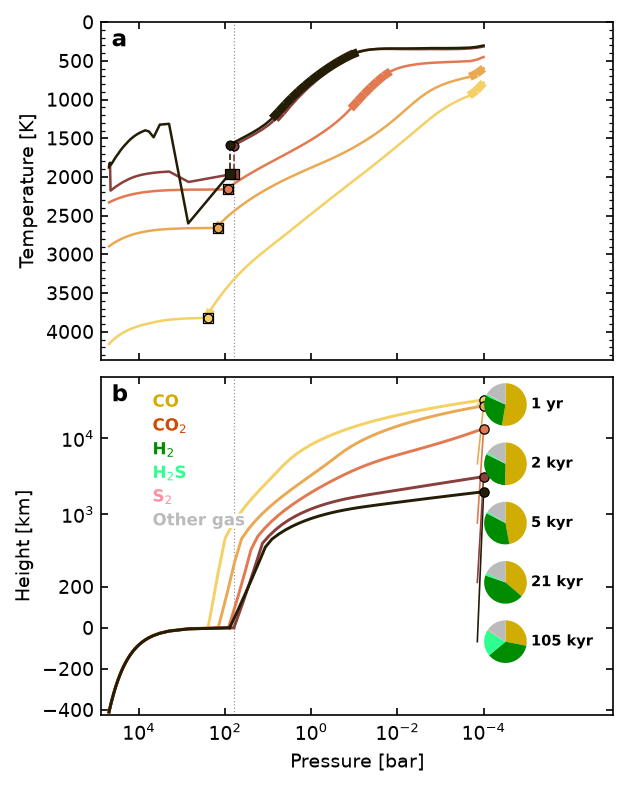

In [10]:
# Log-time colour scale from FIG3_T_COLOUR_MIN_YR, before which the run barely changes;
# earlier snapshots take the first colour
FIG3_T_COLOUR_MIN_YR = 1e3
t_norm = mpl.colors.LogNorm(FIG3_T_COLOUR_MIN_YR, snaps[-1]["t"], clip=True)
cmap_t = cmc.lajolla
col_t = lambda t: cmap_t(0.85 - 0.8 * t_norm(max(t, 1.0)))   # early and hot: pale; late: near black
fmt_t = lambda t: f"{t:.0f} yr" if t < 1e3 else f"{t / 1e3:.0f} kyr"

# SPIDER profiles at the output time nearest each atmosphere snapshot. SPIDER's pressure is zero
# at the top of the mantle, so the atmosphere's surface pressure is added to place the two on one
# axis; its top node is replaced by the surface temperature it reports to PROTEUS (T_magma)
json_files = glob.glob(os.path.join(fav_dir, "data", "*.json"))
json_t = np.array([float(os.path.basename(f).split(".")[0]) for f in json_files])
for s in snaps:
    d = lg.readjson(json_files[int(np.argmin(np.abs(json_t - s["t"])))])
    s["p_int"] = np.r_[0.0, d["pressure_s"]] / 1e5 + s["p_surf"]               # [bar]
    s["T_int"] = np.r_[s["T_magma"], d["temp_s"]]                             # [K]
    s["z_int"] = np.r_[0.0, d["radius_s"] - d["radius_b"][0]] / 1e3           # [km], negative
    print(f"t = {s['t']:10.4g} yr: SPIDER output at {d['time']:10.4g} yr; top cell {d['temp_s'][0]:.0f} K, "
          f"T_magma {s['T_magma']:.0f} K, next cell {d['temp_s'][1]:.0f} K")

p_bot = max(s["p_int"][-1] for s in snaps) * 1.5

fig, (ax_a, ax_b) = plt.subplots(2,1, figsize=(4.4,6), sharex=True)
for s in snaps:
    col = col_t(s["t"])
    ax_a.plot(s["p"], s["T"], color=col, lw=1.2, zorder=2)

    for j in np.flatnonzero(s["conv_cell"]):   # convective cells drawn thick
        ax_a.plot(s["p"][j:j + 2], s["T"][j:j + 2], color=col, lw=4.0, solid_capstyle="butt", zorder=2)

    ax_a.plot(s["p_int"], s["T_int"], color=col, lw=1.2, zorder=2)
    ax_a.plot([s["p_surf"], s["p_surf"]], [s["T_surf"], s["T_magma"]], color=col, lw=0.8, ls="--", zorder=1)
    ax_a.scatter(s["p_surf"], s["T_magma"], marker="s", s=20, color=col, edgecolor="k", lw=0.6, zorder=4)
    ax_a.scatter(s["p_surf"], s["T_surf"], marker="o", s=18, color=col, edgecolor="k", lw=0.6, zorder=5)

    ax_b.plot(s["p"], s["z"], color=col, lw=1.4, zorder=2)
    ax_b.plot(s["p_int"], s["z_int"], color=col, lw=1.4, zorder=2)
    ax_b.scatter(s["p"][0], s["z"][0], s=20, color=col, edgecolor="k", lw=0.6, zorder=4)

p_top = min(s["p"][0] for s in snaps) / 1e3
for ax in (ax_a, ax_b):
    ax.set_xscale("log")
ax_a.set_xlim(p_bot, p_top )
ax_b.set_xlim(p_bot, p_top )   # room on the right for the pies
ax_a.set_ylim(1.05 * max(max(s["T"].max(), s["T_int"].max()) for s in snaps), 0)
for ax in (ax_a, ax_b):
    ax.axvline(min(s["p_surf"] for s in snaps), color="0.6", lw=0.6, ls=":", zorder=0)
ax_a.set_ylabel("Temperature [K]")
z_mantle = -min(s["z_int"].min() for s in snaps)   # mantle depth [km]
ax_b.set_yscale("symlog", linthresh=z_mantle)
ax_b.set_ylim(-1.1 * z_mantle, 2.0 * max(s["z"][0] for s in snaps))
z_ticks = [-400, -200, 0, 200, 1e3, 1e4]
ax_b.set_yticks(z_ticks, [f"{v:.0f}".replace("-", "\u2212") if abs(v) < 1e3 else rf"$10^{{{np.log10(v):.0f}}}$"
                          for v in z_ticks])
ax_b.yaxis.set_minor_locator(mpl.ticker.NullLocator())
ax_b.set_ylabel("Height [km]")
ax_b.set_xlabel("Pressure [bar]")

ticks = [1e4, 1e2, 1e0, 1e-2, 1e-4]
ax_b.set_xticks(ticks)
ax_a.set_xticks(ticks)

for ax, letter in ((ax_a, "a"), (ax_b, "b")):
    ax.text(0.02, 0.98, letter, transform=ax.transAxes, fontweight="bold", fontsize=11, ha="left", va="top")
fig.canvas.draw()   # fix the layout before placing the pies in axes coordinates

# Pies to the right of (b), each linked to the top of its profile; spread vertically so
# they do not overlap, keeping the order of the profile tops
bb = ax_b.get_window_extent()
w_pie = 0.1
h_pie = w_pie * bb.width / bb.height
x_pie = 0.85 - 0.6 * w_pie
to_ax = ax_b.transAxes.inverted()
ends = sorted(((to_ax.transform(ax_b.transData.transform((s["p"][0], s["z"][0]))), s) for s in snaps),
              key=lambda e: e[0][1])
y_pie, y_prev = [], -np.inf
for (xa, ya), _ in ends:
    y_prev = max(ya, y_prev + 1.08 * h_pie, 0.5 * h_pie + 0.02)
    y_pie.append(y_prev)
y_pie = np.array(y_pie) - max(0.0, y_pie[-1] - (1.0 - 0.5 * h_pie))
for ((xa, ya), s), yp in zip(ends, y_pie):
    col = col_t(s["t"])
    x_in = x_pie - 0.55 * w_pie
    x_elbow = x_in - 0.1   # leader: diagonal from the profile top, then flat into the pie
    ax_b.plot([xa, x_in], [ya, yp], color=col, lw=0.8, transform=ax_b.transAxes, zorder=1)
    ax_b.text(x_pie + 0.5 * w_pie, yp, fmt_t(s["t"]), transform=ax_b.transAxes, clip_on=False,
              ha="left", va="center", fontsize=7, color='k', fontweight="bold", path_effects=STROKE)
    pie_ax = ax_b.inset_axes([x_pie - 0.5 * w_pie, yp - 0.5 * h_pie, w_pie, h_pie])
    fr = [s["vmr"].get(sp, 0.0) for sp, *_ in PIE_SPECIES]
    pie_ax.pie(fr + [max(1.0 - sum(fr), 0.0)], colors=[c for *_, c in PIE_SPECIES] + [PIE_OTHER[1]],
               startangle=90, counterclock=False, wedgeprops=dict(lw=0))
    # pie_ax.add_patch(Circle((0, 0), 1.1, fill=False, edgecolor=col, lw=1.6))
    pie_ax.set_xlim(-1.2, 1.2)
    pie_ax.set_ylim(-1.2, 1.2)

# Pie key as coloured text in the empty upper left of (b)
for k, (lab, col) in enumerate([(lab, c) for _, lab, c in PIE_SPECIES] + [PIE_OTHER]):
    ax_b.text(0.1, 0.95 - 0.07 * k, lab, transform=ax_b.transAxes, fontsize=8, va="top",
              color=col, fontweight="bold", path_effects=STROKE)

fig.subplots_adjust(hspace=0.05)
fig.savefig(os.path.join(outdir, "fig3_atmosphere_interior_favourite.pdf"), bbox_inches="tight")
plt.show()


## Appendix: carbon partition against time across the grid

Escape-on runs of the loaded planet mass, one panel per grid point: fO2 across, initial mantle carbon down. Each panel stacks the carbon reservoirs of Figure 2 (same colours and hatching, defined in its cell) against time, as fractions of the planet's carbon at the start of the run: graphite, the carbon in atmospheric CO, CO$_2$ and CH$_4$, and escaped, the drop in the total carbon since the start. A panel ends where its run ends. The cell prints the largest gap between the stack and 1, which is the carbon dissolved in the melt or trapped in the solid plus round-off.

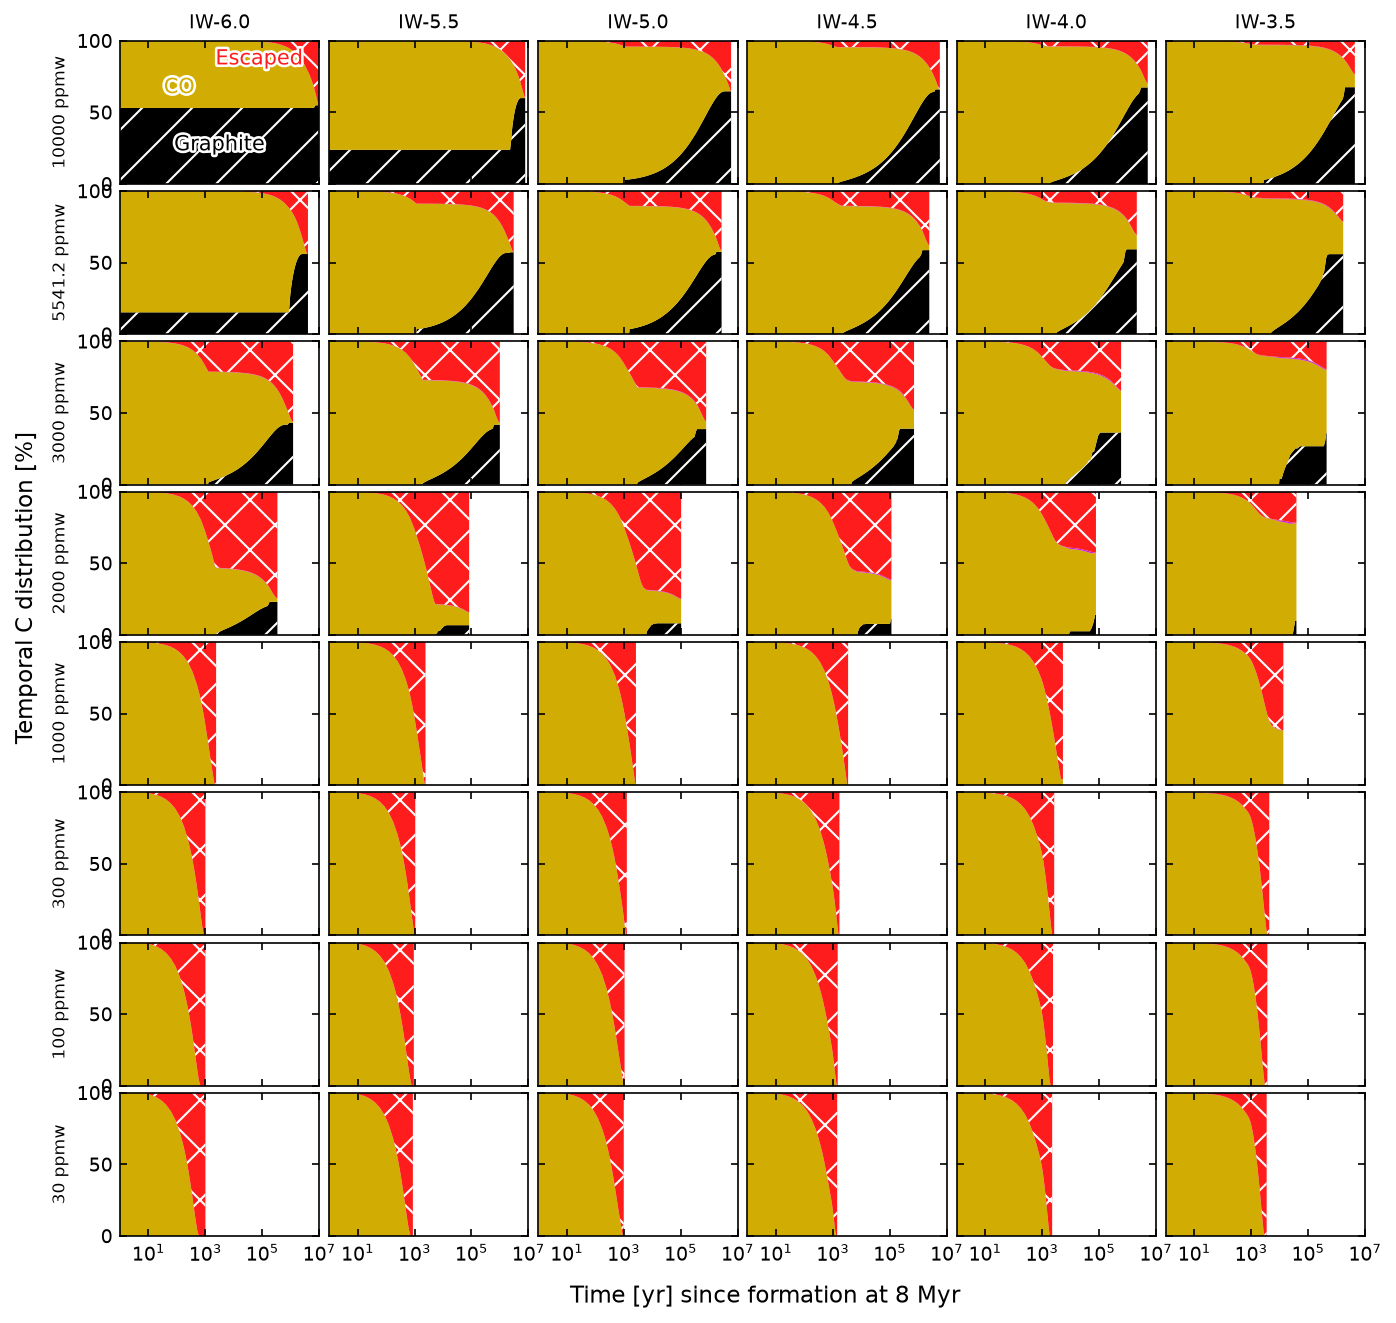

Saturation on: largest |100 - stack| 1.23e-01 %


In [11]:
hf_of = {(x, y, on, e): hf for hf, x, y, on, e in zip(helps, dIW, Cb, cond, eta)}

def carbon_fractions(hf):
    """Times > 0 [yr], and each reservoir of C_RESERVOIRS as a fraction of the carbon at t = 0."""
    t = np.array(hf["Time"], dtype=float)
    ok = t > 0
    col = lambda k: np.array(hf[k], dtype=float)[ok]
    c0 = float(hf["C_kg_total"].iloc[0])
    frac = {"graphite": col("C_kg_condensed") / c0,
            "escaped": (c0 - col("C_kg_total")) / c0}
    frac.update({sp: col(f"{sp}_kg_atm") * carbon_mass_fraction(comp) / c0
                 for sp, comp in C_SPECIES.items()})
    return t[ok], frac

def plot_carbon_partition(sat_on, e=ETA_ON):
    """Stacked carbon reservoirs against time, one panel per grid point."""
    xs_p, rows_p = np.unique(dIW), np.unique(Cb)[::-1]   # carbon budget decreasing downwards
    fig, axs = plt.subplots(len(rows_p), len(xs_p), figsize=(10, 1.2 * len(rows_p)),
                            sharex=True, sharey=True)
    t_lo, t_hi, gap = np.inf, 0.0, 0.0
    for i, c in enumerate(rows_p):
        for k, x in enumerate(xs_p):
            ax = axs[i, k]
            hf = hf_of.get((x, c, sat_on, e))
            if hf is not None:
                t, frac = carbon_fractions(hf)
                bottom = np.zeros_like(t)
                for key in C_RESERVOIRS.keys():
                    _, _, colour, hatch = C_RESERVOIRS[key]
                    top = bottom + np.clip(frac[key]*100, 0.0, None)
                    ax.fill_between(t, bottom, top, color=colour, lw=0, hatch=hatch, hatchcolor="w")
                    bottom = top
                gap = max(gap, np.abs(100.0 - bottom).max())
                t_lo, t_hi = min(t_lo, t[0]), max(t_hi, t[-1])
            if i == 0:
                ax.set_title(f"IW{x:+.1f}", fontsize=9)
            if k == 0:
                ax.set_ylabel(f"{c:g} ppmw", fontsize=8)
            ax.tick_params(which="minor", left=False, right=False)

    for anno in (
        ("graphite", "Graphite", 0.5, 0.2, 0, 0),
        ("escaped", "Escaped", 0.7, 0.8, 0, 0),
        ("CO", r"CO", 0.3, 0.6, 0, 0)
    ):
        axs[anno[4], anno[5]].annotate(
                      anno[1], (anno[2], anno[3]), xycoords="axes fraction",
                      ha="center", va="bottom", fontsize=10, 
                      color=C_RESERVOIRS[anno[0]][2],
                      path_effects=STROKE)
        
    axs[0, 0].set_xscale("log")
    axs[0, 0].set_xlim(t_lo, t_hi)
    axs[0,0].set_xticks([1e1,  1e3,  1e5, 1e7])
    axs[0, 0].set_ylim(0.0, 100.0)
    axs[0, 0].set_yticks([0, 50, 100])

    fig.supxlabel("Time [yr] since formation at {:.0f} Myr".format(ini_age),
                  x=0.5, y=0.0)
    fig.supylabel("Temporal C distribution [%]",y=0.5, x=0)

    fig.subplots_adjust(hspace=0.05, wspace=0.05, bottom=0.05, left=0.07)
    fig.savefig(os.path.join(outdir, f"appendix_carbon_partition_sat{int(sat_on)}_eta{e:g}.pdf"),
                bbox_inches="tight")
    plt.show()
    print(f"Saturation {'on' if sat_on else 'off'}: largest |100 - stack| {gap:.2e} %")

plot_carbon_partition(True)